In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


# Computer Intelligence Lab 1

## Telco Customer Churn Analysis

### Introduction

In this lab, we are going to analyze the Telco Customer Churn dataset using Python in Kaggle. The purpose of this analysis is to understand why customers stop using a telecommunications company's services.

First, we will load the dataset and display its first and last rows. Next, we will preprocess the data by converting churn values from Yes and No to 1 and 0, checking data types, and handling missing values.

After cleaning the dataset, we will explore how customer characteristics such as gender, senior citizen status, partner status, and dependents relate to churn. We will also analyze phone services, contract types, paperless billing, and payment methods.

We will use Pandas for data processing and Matplotlib and Seaborn for data visualization. This analysis will help us understand the factors associated with customers leaving the company.

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:

# Display the first 5 rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Interpretation of the Head

The `df.head()` function displays the first five rows of the dataset. Each row represents a customer, while the columns show different customer attributes such as gender, services, payment information, and churn status. This helps us understand how the dataset is organized.

In [4]:

# Display the last 5 rows
df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### Interpretation of the Tail

The `df.tail()` function displays the last five rows of the dataset. This helps us examine the records at the end of the dataset and confirm that the customer information follows the same structure as the first rows.

## 4. Data Preprocessing

Data preprocessing is the process of cleaning and preparing data before analysis. In this section, we will convert the churn values into numbers, examine and correct data types, and identify and handle missing values.

### 4.1 Converting Churn Values from Yes/No to 1/0

In [5]:

# Display churn values before conversion
print("Churn values before conversion:")
print(df['Churn'].value_counts())

# Convert Yes to 1 and No to 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Display churn values after conversion
print("\nChurn values after conversion:")
print(df['Churn'].value_counts())


Churn values before conversion:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn values after conversion:
Churn
0    5174
1    1869
Name: count, dtype: int64


### Interpretation

The Churn column was successfully converted from categorical values into numerical values. Customers who left the company are represented by 1, while customers who stayed are represented by 0.

The results show that 5,174 customers stayed with the company, while 1,869 customers left. This indicates that the majority of customers did not churn. Converting the values into numbers makes the churn attribute easier to use in numerical analysis.

### 4.2 Checking and Changing Data Types

In this section, we examine the data types of all columns in the dataset and convert columns into appropriate data types where necessary.

In [6]:

# Display the data type of each column
print("Data types before conversion:")
print(df.dtypes)


Data types before conversion:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object


In [7]:

# Convert TotalCharges from text to decimal numbers
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

# Display the data types after conversion
print("Data types after conversion:")
print(df.dtypes)


Data types after conversion:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


### Interpretation of Data Types

The data types of all 21 columns were displayed using `df.dtypes`. The results showed that most columns contain categorical data stored as objects, while columns such as tenure, SeniorCitizen, and MonthlyCharges contain numerical values.

The TotalCharges column was initially stored as an object even though it represents numerical payment information. Therefore, it was converted into float64 using the `pd.to_numeric()` function.

During conversion, values that could not be converted into numbers were replaced with NaN. These missing values will be handled during the next preprocessing step.

### 4.3 Identifying and Removing Missing Values

Missing values can affect the accuracy of data analysis. In this section, we identify columns containing missing values, remove records with missing information, and verify that the dataset is clean.

In [8]:

# Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [9]:

# Display only columns with missing values
missing_values = df.isnull().sum()

print("Columns containing missing values:")
print(missing_values[missing_values > 0])


Columns containing missing values:
TotalCharges    11
dtype: int64


In [10]:

# Display the number of rows before cleaning
print("Rows before cleaning:", df.shape[0])

# Remove rows containing missing values
df = df.dropna()

# Display the number of rows after cleaning
print("Rows after cleaning:", df.shape[0])


Rows before cleaning: 7043
Rows after cleaning: 7032


In [11]:

# Verify that there are no missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

# Display the cleaned dataset dimensions
print("\nCleaned dataset shape:", df.shape)


Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Cleaned dataset shape: (7032, 21)


### Interpretation of Missing Values

The dataset was checked for missing values using the `isnull().sum()` function. The results showed that the TotalCharges column contained 11 missing values, while the other columns had no missing values.

The missing values were removed using the `dropna()` function. Before cleaning, the dataset contained 7,043 rows and 21 columns. After removing the missing values, the dataset contained 7,032 rows and 21 columns.

A final check confirmed that no missing values remained in the dataset. The cleaned dataset is now ready for data exploration and visualization.

## 5. Data Exploration

Data exploration helps us understand patterns and relationships in the dataset. In this section, we will examine how different customer characteristics, services, and payment methods are associated with customer churn.

### 5.1 Demographic Analysis

#### 5.1.1 Gender Distribution Against Churn

This analysis examines the relationship between customer gender and churn to determine whether male or female customers are more likely to leave the company.

Gender Distribution Against Churn:
Churn      0    1
gender           
Female  2544  939
Male    2619  930


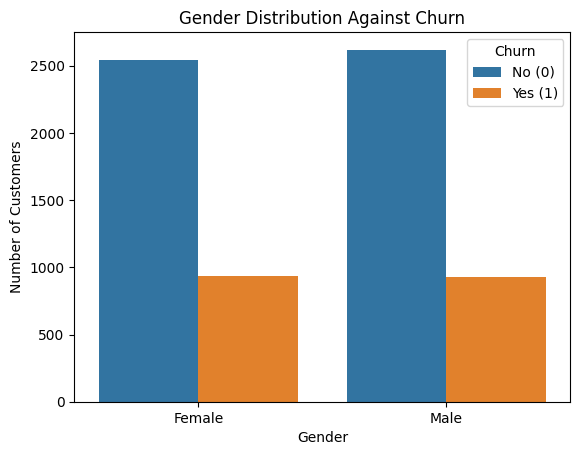

In [12]:

# Gender distribution against Churn
gender_churn = pd.crosstab(df['gender'], df['Churn'])

# Display the results
print("Gender Distribution Against Churn:")
print(gender_churn)

# Create a bar chart
sns.countplot(data=df, x='gender', hue='Churn')

plt.title('Gender Distribution Against Churn')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [13]:

# Calculate churn percentage for each gender
gender_churn_percentage = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100

print("Gender Churn Percentage:")
print(gender_churn_percentage.round(2))


Gender Churn Percentage:
Churn       0      1
gender              
Female  73.04  26.96
Male    73.80  26.20


### Interpretation of Gender Distribution Against Churn

The analysis shows that both male and female customers experience customer churn. Among female customers, 2,544 stayed with the company while 939 left. Among male customers, 2,619 stayed while 930 left.

The churn percentage for female customers is approximately 26.96%, compared to 26.20% for male customers.

This shows that female customers have a slightly higher churn rate than male customers. However, the difference is very small, suggesting that gender does not have a strong relationship with customer churn in this dataset.

#### 5.1.2 SeniorCitizen Against Churn

This analysis examines the relationship between senior citizen status and customer churn. The purpose is to determine whether senior citizens are more likely to leave the telecommunications company compared to non-senior citizens.

In the dataset, 0 represents non-senior citizens while 1 represents senior citizens.

SeniorCitizen Distribution Against Churn:
Churn             0     1
SeniorCitizen            
0              4497  1393
1               666   476


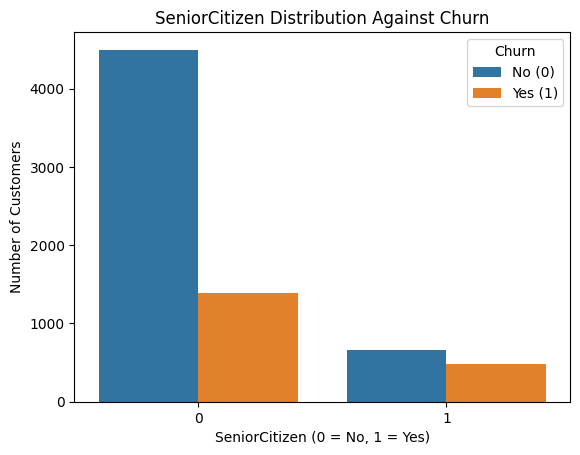

In [14]:

# SeniorCitizen distribution against Churn
senior_churn = pd.crosstab(df['SeniorCitizen'], df['Churn'])

# Display the results
print("SeniorCitizen Distribution Against Churn:")
print(senior_churn)

# Create a bar chart
sns.countplot(data=df, x='SeniorCitizen', hue='Churn')

plt.title('SeniorCitizen Distribution Against Churn')
plt.xlabel('SeniorCitizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [15]:

# Calculate churn percentage for each SeniorCitizen group
senior_churn_percentage = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

print("SeniorCitizen Churn Percentage:")
print(senior_churn_percentage.round(2))


SeniorCitizen Churn Percentage:
Churn              0      1
SeniorCitizen              
0              76.35  23.65
1              58.32  41.68


### Interpretation of SeniorCitizen Against Churn

The analysis shows that senior citizens have a higher churn rate compared to non-senior citizens.

Among non-senior citizens, 4,497 customers stayed with the company while 1,393 left. For senior citizens, 666 customers stayed while 476 left.

The percentage analysis shows that approximately 23.65% of non-senior citizens left the company, compared to 41.68% of senior citizens.

This indicates that senior citizens are more likely to leave the company than non-senior citizens in this dataset. Therefore, senior citizen status is an important factor associated with customer churn.

#### 5.1.3 Partner Against Churn

This analysis examines the relationship between having a partner and customer churn. The objective is to determine whether customers with partners are more or less likely to leave the telecommunications company compared to customers without partners.

Partner Distribution Against Churn:
Churn       0     1
Partner            
No       2439  1200
Yes      2724   669


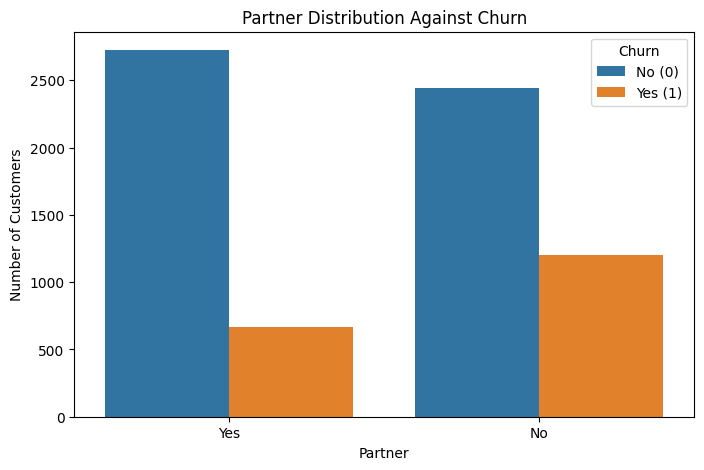

In [16]:

# Partner distribution against Churn
partner_churn = pd.crosstab(df['Partner'], df['Churn'])

# Display the results
print("Partner Distribution Against Churn:")
print(partner_churn)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Partner', hue='Churn')

plt.title('Partner Distribution Against Churn')
plt.xlabel('Partner')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [17]:

# Calculate churn percentage for each Partner group
partner_churn_percentage = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

print("Partner Churn Percentage:")
print(partner_churn_percentage.round(2))


Partner Churn Percentage:
Churn        0      1
Partner              
No       67.02  32.98
Yes      80.28  19.72


### Interpretation of Partner Against Churn

The analysis shows that customers without partners have a higher churn rate compared to customers with partners.

Among customers without partners, 2,439 stayed with the company while 1,200 left. Among customers with partners, 2,724 stayed while 669 left.

The percentage analysis shows that approximately 32.98% of customers without partners left the company, compared to 19.72% of customers with partners.

This indicates that customers without partners are more likely to leave the company than those with partners. Therefore, partner status is an important factor associated with customer churn in this dataset.

#### 5.1.4 Dependents Against Churn

This analysis examines the relationship between having dependents and customer churn. The purpose is to determine whether customers with dependents are more or less likely to leave the telecommunications company compared to customers without dependents.

Dependents Distribution Against Churn:
Churn          0     1
Dependents            
No          3390  1543
Yes         1773   326


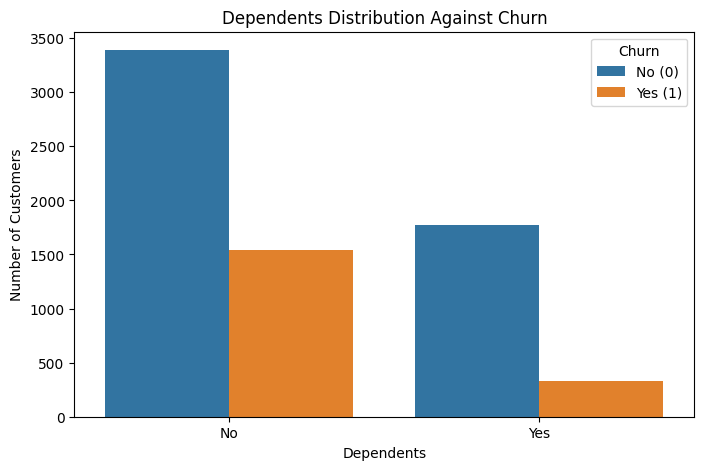

In [18]:

# Dependents distribution against Churn
dependents_churn = pd.crosstab(df['Dependents'], df['Churn'])

# Display the results
print("Dependents Distribution Against Churn:")
print(dependents_churn)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Dependents',
    hue='Churn',
    hue_order=[0, 1]
)

plt.title('Dependents Distribution Against Churn')
plt.xlabel('Dependents')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [19]:

# Calculate churn percentage for each Dependents group
dependents_churn_percentage = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print("Dependents Churn Percentage:")
print(dependents_churn_percentage.round(2))


Dependents Churn Percentage:
Churn           0      1
Dependents              
No          68.72  31.28
Yes         84.47  15.53


### Interpretation of Dependents Against Churn

The analysis shows that customers without dependents have a higher churn rate compared to customers with dependents.

Among customers without dependents, 3,390 stayed with the company while 1,543 left. Among customers with dependents, 1,773 stayed while 326 left.

The percentage analysis shows that approximately 31.28% of customers without dependents left the company, compared to 15.53% of customers with dependents.

This indicates that customers without dependents are more likely to leave the company than customers with dependents. Therefore, having dependents is associated with a lower churn rate in this dataset.

### 5.2 Service Analysis

#### 5.2.1 PhoneService Against Churn

This analysis examines the relationship between phone service subscription and customer churn. The objective is to determine whether customers who have phone service are more or less likely to leave the telecommunications company compared to those without phone service.

PhoneService Distribution Against Churn:
Churn            0     1
PhoneService            
No             510   170
Yes           4653  1699


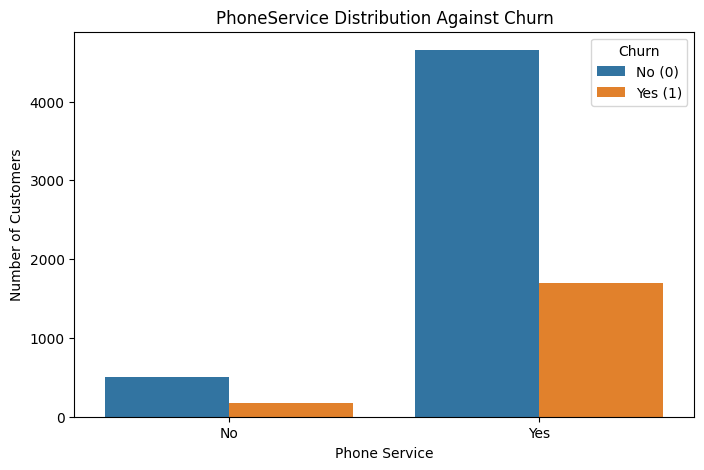

In [20]:

# PhoneService distribution against Churn
phone_churn = pd.crosstab(df['PhoneService'], df['Churn'])

# Display the results
print("PhoneService Distribution Against Churn:")
print(phone_churn)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='PhoneService',
    hue='Churn',
    hue_order=[0, 1]
)

plt.title('PhoneService Distribution Against Churn')
plt.xlabel('Phone Service')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [21]:

# Calculate churn percentage for each PhoneService group
phone_churn_percentage = pd.crosstab(
    df['PhoneService'],
    df['Churn'],
    normalize='index'
) * 100

print("PhoneService Churn Percentage:")
print(phone_churn_percentage.round(2))


PhoneService Churn Percentage:
Churn             0      1
PhoneService              
No            75.00  25.00
Yes           73.25  26.75


### Interpretation of PhoneService Against Churn

The analysis shows that most customers in the dataset have phone service.

Among customers with phone service, 4,653 stayed with the company while 1,699 left. Among customers without phone service, 510 stayed while 170 left.

The percentage analysis shows that approximately 26.75% of customers with phone service left the company, compared to 25.00% of customers without phone service.

This indicates that customers with phone service have a slightly higher churn rate than those without phone service. However, the difference is small, suggesting that phone service subscription does not have a strong relationship with customer churn in this dataset.

### 5.3 Payments Analysis

#### 5.3.1 Contract Against Churn

This analysis examines the relationship between customer contract type and churn. The objective is to determine whether customers with month-to-month, one-year, or two-year contracts are more likely to leave the telecommunications company.

Contract Distribution Against Churn:
Churn              0     1
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48


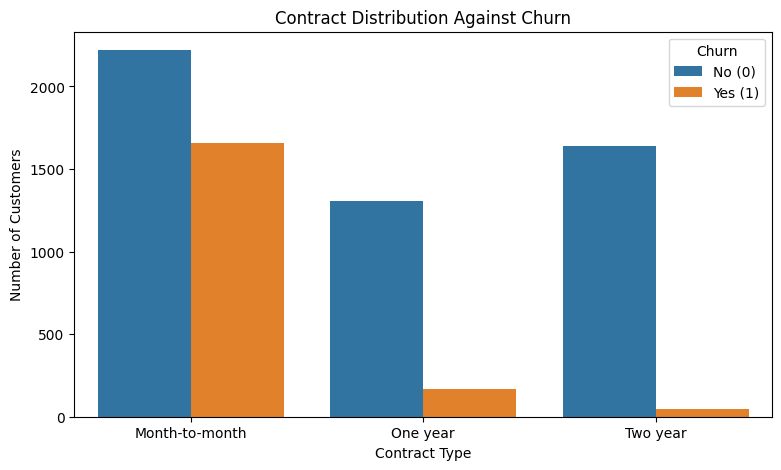

In [22]:

# Contract distribution against Churn
contract_churn = pd.crosstab(df['Contract'], df['Churn'])

# Display the results
print("Contract Distribution Against Churn:")
print(contract_churn)

# Create a bar chart
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn',
    hue_order=[0, 1],
    order=['Month-to-month', 'One year', 'Two year']
)

plt.title('Contract Distribution Against Churn')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [23]:

# Calculate churn percentage for each Contract type
contract_churn_percentage = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print("Contract Churn Percentage:")
print(contract_churn_percentage.round(2))


Contract Churn Percentage:
Churn               0      1
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


### Interpretation of Contract Against Churn

The analysis shows that contract type is strongly associated with customer churn.

Among customers with month-to-month contracts, 2,220 stayed with the company while 1,655 left. For one-year contracts, 1,306 stayed while 166 left. For two-year contracts, 1,637 stayed while only 48 left.

The percentage analysis shows that month-to-month customers have the highest churn rate at 42.71%, followed by one-year customers at 11.28%. Customers with two-year contracts have the lowest churn rate at 2.85%.

This indicates that customers with shorter contracts are more likely to leave the company than customers with longer contracts.

Therefore, the company could consider offering attractive long-term contract plans to encourage customer retention. However, the analysis shows an association rather than proving that longer contracts directly prevent churn.

#### 5.3.2 PaperlessBilling Against Churn

This analysis examines the relationship between paperless billing and customer churn. The objective is to determine whether customers who use paperless billing are more or less likely to leave the telecommunications company compared to those who do not use paperless billing.

PaperlessBilling Distribution Against Churn:
Churn                0     1
PaperlessBilling            
No                2395   469
Yes               2768  1400


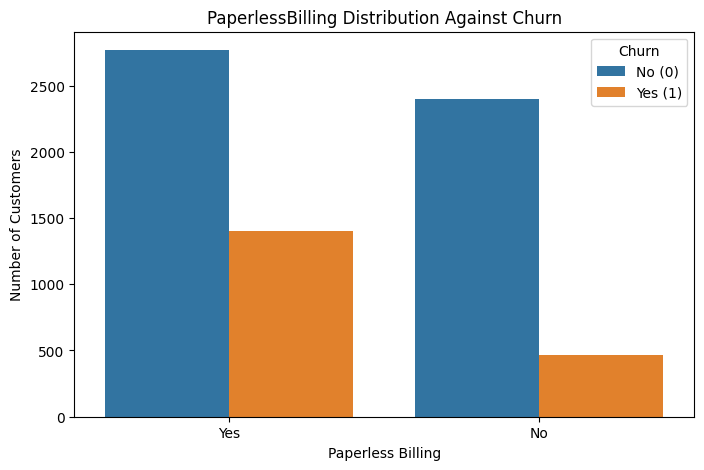

In [24]:

# PaperlessBilling distribution against Churn
paperless_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn']
)

# Display the results
print("PaperlessBilling Distribution Against Churn:")
print(paperless_churn)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='PaperlessBilling',
    hue='Churn',
    hue_order=[0, 1]
)

plt.title('PaperlessBilling Distribution Against Churn')
plt.xlabel('Paperless Billing')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()


In [25]:

# Calculate churn percentage for each PaperlessBilling group
paperless_churn_percentage = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

print("PaperlessBilling Churn Percentage:")
print(paperless_churn_percentage.round(2))


PaperlessBilling Churn Percentage:
Churn                 0      1
PaperlessBilling              
No                83.62  16.38
Yes               66.41  33.59


### Interpretation of PaperlessBilling Against Churn

The analysis shows that customers using paperless billing have a higher churn rate compared to customers who do not use paperless billing.

Among customers using paperless billing, 2,768 stayed with the company while 1,400 left. Among customers not using paperless billing, 2,395 stayed while 469 left.

The percentage analysis shows that approximately 33.59% of customers using paperless billing left the company, compared to 16.38% of customers not using paperless billing.

This indicates that customers using paperless billing are more likely to leave the company than those who do not use it. Therefore, paperless billing is an important factor associated with customer churn in this dataset. However, this relationship does not necessarily mean that paperless billing directly causes customers to leave.

#### 5.3.3 PaymentMethod Against Churn

This analysis examines the relationship between payment methods and customer churn. The objective is to determine which payment method has the highest number and percentage of customers leaving the telecommunications company.

The payment methods considered include electronic check, mailed check, automatic bank transfer, and automatic credit card payments.

PaymentMethod Distribution Against Churn:
Churn                         0     1
PaymentMethod                        
Bank transfer (automatic)  1284   258
Credit card (automatic)    1289   232
Electronic check           1294  1071
Mailed check               1296   308


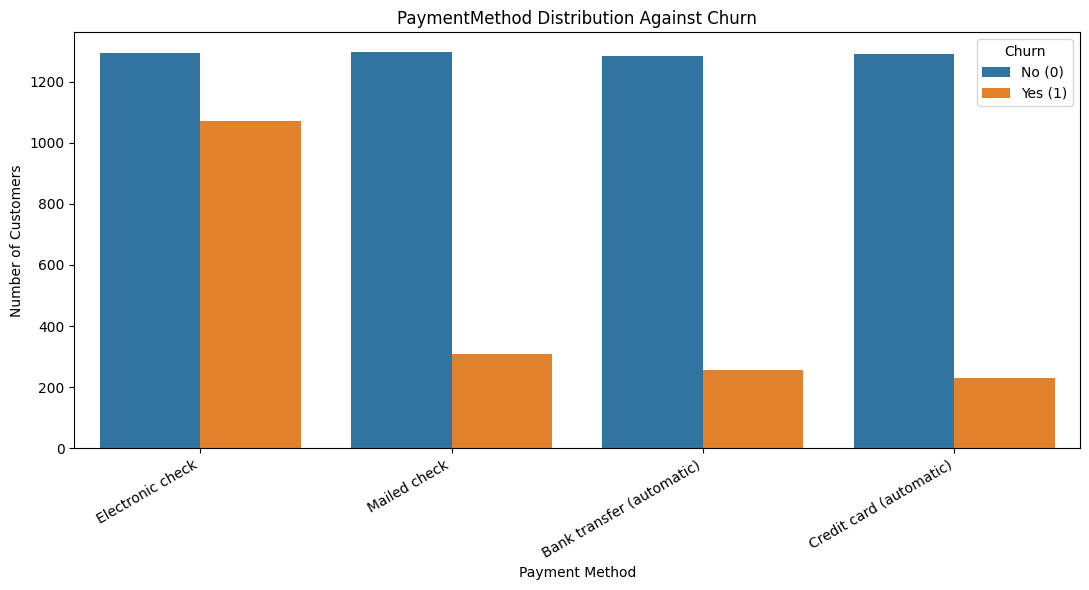

In [26]:

# PaymentMethod distribution against Churn
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn']
)

# Display the results
print("PaymentMethod Distribution Against Churn:")
print(payment_churn)

# Create a bar chart
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn',
    hue_order=[0, 1]
)

plt.title('PaymentMethod Distribution Against Churn')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.tight_layout()
plt.show()


In [27]:

# Calculate churn percentage for each PaymentMethod
payment_churn_percentage = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print("PaymentMethod Churn Percentage:")
print(payment_churn_percentage.round(2))


PaymentMethod Churn Percentage:
Churn                          0      1
PaymentMethod                          
Bank transfer (automatic)  83.27  16.73
Credit card (automatic)    84.75  15.25
Electronic check           54.71  45.29
Mailed check               80.80  19.20


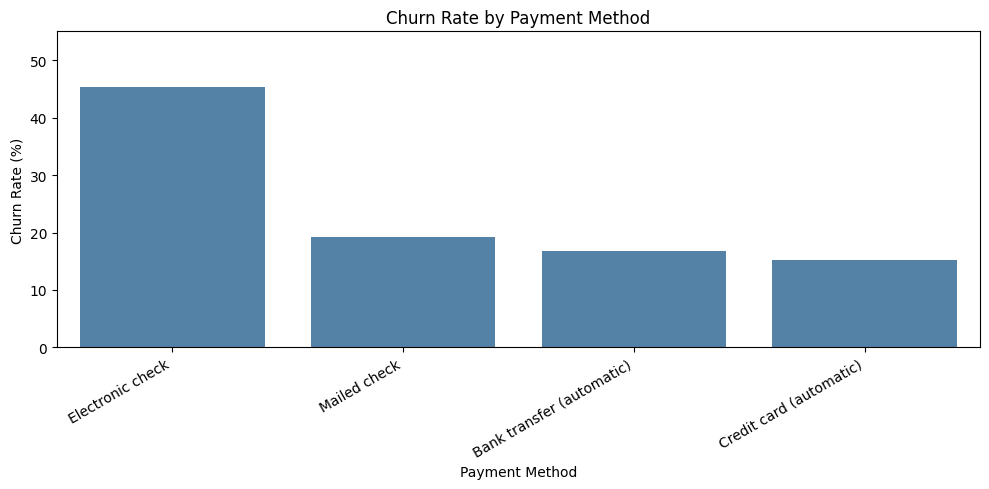

In [28]:

# Calculate churn rates by payment method
payment_rates = (
    df.groupby('PaymentMethod')['Churn']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Plot churn percentages
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_rates.index,
    y=payment_rates.values,
    color='steelblue'
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 55)
plt.tight_layout()
plt.show()


### Interpretation of PaymentMethod Against Churn

The analysis shows that customer churn varies across different payment methods.

Among customers using electronic checks, 1,294 stayed with the company while 1,071 left. For mailed checks, 1,296 stayed while 308 left. Among customers using automatic bank transfers, 1,284 stayed while 258 left. For automatic credit card payments, 1,289 stayed while 232 left.

The percentage analysis shows that electronic check customers have the highest churn rate at 45.29%, followed by mailed check customers at 19.20%, automatic bank transfer customers at 16.73%, and automatic credit card customers at 15.25%.

This indicates that customers using electronic checks are more likely to leave the company compared to those using other payment methods.

Therefore, payment method is an important factor associated with customer churn. The company could investigate why electronic check users have a higher churn rate and consider ways to encourage customer retention. However, this analysis does not prove that the payment method itself causes churn.

## 6. Conclusion

In this lab, we analyzed the Telco Customer Churn dataset using Python in Kaggle. The dataset was loaded, examined, and cleaned by converting churn values into numbers, correcting data types, and removing missing values.

After preprocessing, the dataset contained 7,032 customer records and 21 attributes.

The analysis showed that senior citizens, customers without partners, and customers without dependents had higher churn rates than their comparison groups. Gender and phone service showed only small differences in churn rates.

The payment analysis showed that customers with month-to-month contracts had the highest churn rate compared to those with one-year and two-year contracts. Customers using paperless billing also had a higher churn rate than those who did not use it. Additionally, electronic check users had the highest churn rate among the four payment methods.

Overall, contract type, payment method, paperless billing, and certain demographic characteristics were associated with customer churn. These findings can help the telecommunications company identify customer groups that may need greater attention and develop strategies to improve customer retention.

In [29]:

# Final verification of the cleaned dataset

print("FINAL DATASET VERIFICATION")
print("--------------------------")

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Check missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Check churn values
print("Churn Values:", sorted(df['Churn'].unique()))

# Check TotalCharges data type
print("TotalCharges Data Type:", df['TotalCharges'].dtype)

# Confirm data is ready
if (df.shape == (7032, 21)
    and df.isnull().sum().sum() == 0
    and set(df['Churn'].unique()) == {0, 1}
    and pd.api.types.is_numeric_dtype(df['TotalCharges'])):
    print("Dataset verification passed!")
else:
    print("Please review the preprocessing steps.")


FINAL DATASET VERIFICATION
--------------------------
Dataset Shape: (7032, 21)
Total Missing Values: 0
Churn Values: [np.int64(0), np.int64(1)]
TotalCharges Data Type: float64
Dataset verification passed!
